# 05 · Single-species, shared MLP — previous year → next year

One **small feed-forward network** (default 64 → 32 → 16 hidden units) is trained across **all selected grid squares for one species**. For each square and year `t`, it learns to predict the count in `t` from **the immediately previous calendar year** `t−1`.

- Inputs: `log1p(previous_count)` **and a separate missing-observation indicator**. An observed zero and an unobserved square-year are different.
- Training targets: only **observed counts**. Absent species–square–years are never manufactured as zero targets.
- Evaluation: fixed-origin, with predictions **recursively fed back** for every test year. The model never sees test bird counts, and even bridges excluded survey years such as 2020 without reading hidden actuals.
- One trained model is shared across the squares; it is **not a spatially connected network**. Coordinates and climate are intentionally excluded in this first baseline.

Run `01_download_and_preprocess.ipynb` before this notebook. Requires PyTorch (`python -m pip install torch`), NumPy, Pandas, and Matplotlib.

## 1 · Settings and data

In [ ]:
from dataclasses import asdict
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "ukbbs" / "forecasting.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the ukbbs-workflow repository")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ukbbs.forecasting import ForecastTask, LastValueForecaster, chronological_split
from ukbbs.evaluation import run_forecast
from ukbbs.storage import save_forecast_results
from ukbbs.mlp import MLPConfig, OneYearMLPForecaster

SPECIES = "CU"
FORECAST_ORIGIN = 2018       # Last calendar year used to fit the model.
TEST_END_YEAR = 2024         # Must exceed origin; observations in between can be sparse.
MAX_SITES = 300              # Small run first; set to None for all training squares.
SAVE_PREDICTIONS = True     # Set True once you're happy with your experiment.

CONFIG = MLPConfig(
    hidden_sizes=(64, 32, 16),
    epochs=150,
    learning_rate=0.001,
    batch_size=512,
    weight_decay=0.0001,
    seed=42,
)

data_path = PROJECT_ROOT / "data" / "processed" / "ukbbs_model_data.csv"
if not data_path.is_file():
    raise FileNotFoundError("Run notebook 01 first; processed BBS counts are missing")
observations = pd.read_csv(
    data_path, dtype={"OS_GRID_REF": "string", "species": "string"}
)
observations = observations.loc[observations["species"].eq(SPECIES)].copy()
if observations.empty:
    raise ValueError(f"No observations for species {SPECIES!r}")
print(f"{SPECIES}: {len(observations):,} observed rows; ",
      f"{observations.OS_GRID_REF.nunique():,} squares")

CU: 16,553 observed rows;  2,794 squares


## 2 · Chronological train/test split

Choose squares **from training data only** so we do not introduce new sites based on what happens during the test period. We use identical evaluated rows for the MLP and last-value baseline. Test rows are the observations we want to score; missing test observations do not contribute to metrics. The model generates recursive forecasts for intervening years anyway.

In [2]:
task = ForecastTask()
train, test = chronological_split(
    observations, train_through=FORECAST_ORIGIN, task=task
)
train_site_counts = train.groupby("OS_GRID_REF").size().sort_values(ascending=False)
training_squares = train_site_counts.index
if MAX_SITES is not None:
    training_squares = training_squares[:MAX_SITES]
train = train.loc[train.OS_GRID_REF.isin(training_squares)].copy()
test = test.loc[
    test.OS_GRID_REF.isin(training_squares)
    & test.year.le(TEST_END_YEAR)
].copy()
if train.empty or test.empty:
    raise ValueError("No training and test rows remain; change species/origin/site settings")
print(f"Train: {len(train):,} observed rows across {train.OS_GRID_REF.nunique():,} squares")
print(f"Test: {len(test):,} observed rows, years {test.year.min()}–{test.year.max()}")
print(f"A test-year gap (e.g. 2020) is still traversed during recursive prediction.")

Train: 5,199 observed rows across 300 squares
Test: 747 observed rows, years 2019–2024
A test-year gap (e.g. 2020) is still traversed during recursive prediction.


## 3 · Train MLP and evaluate without future observations

`run_forecast()` calls `fit(train, task)` and then passes the test frame **without the target column** to `predict()`. For 2019 onward, the MLP starts from counts observed in 2018. If the next step is 2020, it uses its **2019 prediction**, not the real count from 2019. This is a fixed-origin benchmark, not annual updating.

Training examples are `(square, y−1) → (square, y)` matched by calendar year; no 2000→2002 pair is fabricated if 2001 is absent. Previous-year missing inputs have a separate indicator and zero-filled numeric channel; real zeros have indicator 0.

In [3]:
mlp = OneYearMLPForecaster(config=CONFIG)
mlp_report = run_forecast(mlp, train, test, task)
naive_report = run_forecast(LastValueForecaster(), train, test, task)

print(f"MLP supervised training pairs: {mlp.n_training_pairs_:,}")
print(f"Pairs with missing preceding year: {mlp.n_missing_previous_:,}")
display(pd.DataFrame({
    "MLP": mlp_report.metrics,
    "Last observed value": naive_report.metrics,
}))
display(mlp_report.predictions.head())

MLP supervised training pairs: 5,054
Pairs with missing preceding year: 883


,MLP,Last observed value
n_scored,747.000000,747.000000
n_unscored,0.000000,0.000000
mae,4.050770,3.887550
rmse,7.954911,8.064001
bias,2.659930,-0.299866


,OS_GRID_REF,species,year,max_total_count_over_all_distance_bands_for_max_visit,prediction,residual,absolute_error
0,HY3615,CU,2019,7.0,3.694711,3.305289,3.305289
1,HY4711,CU,2019,16.0,6.609656,9.390344,9.390344
2,ID1412,CU,2019,1.0,1.980820,-0.980820,0.980820
3,ID3100,CU,2019,2.0,2.493432,-0.493432,0.493432
4,IH1464,CU,2019,8.0,5.907344,2.092656,2.092656


## 4 · Training loss and accuracy by forecast year

Test MAE is measured **only where a bird count is observed**. Later years are harder because the MLP feeds its own predictions into subsequent years; it never obtains newly observed test values.

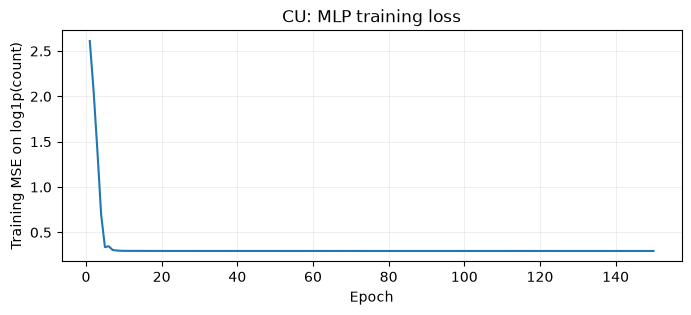

,model,year,n_scored,mae
0,MLP,2019,180,3.013230
1,MLP,2021,153,3.885602
2,MLP,2022,142,4.054333
3,MLP,2023,132,5.147236
4,MLP,2024,140,4.527833
5,Last observed,2019,180,3.172222
6,Last observed,2021,153,3.588235
7,Last observed,2022,142,3.845070
8,Last observed,2023,132,4.962121
9,Last observed,2024,140,4.164286


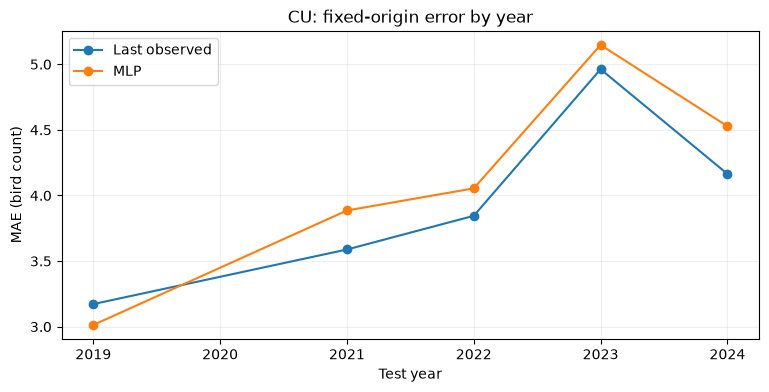

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1, len(mlp.history_) + 1), mlp.history_)
ax.set(xlabel="Epoch", ylabel="Training MSE on log1p(count)", title=f"{SPECIES}: MLP training loss")
ax.grid(alpha=0.2)
plt.show()

by_year = []
for model_name, result in [("MLP", mlp_report), ("Last observed", naive_report)]:
    for year, group in result.predictions.groupby("year", sort=True):
        scored = group.loc[group[task.target].notna()].copy()
        if scored.empty:
            continue
        by_year.append({
            "model": model_name,
            "year": int(year),
            "n_scored": len(scored),
            "mae": float(scored["absolute_error"].mean()),
        })
metrics_by_year = pd.DataFrame(by_year)
display(metrics_by_year)
fig, ax = plt.subplots(figsize=(9, 4))
for model_name, group in metrics_by_year.groupby("model"):
    ax.plot(group.year, group.mae, marker="o", label=model_name)
ax.set(xlabel="Test year", ylabel="MAE (bird count)", title=f"{SPECIES}: fixed-origin error by year")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 5 · Plot one square's observed and predicted counts

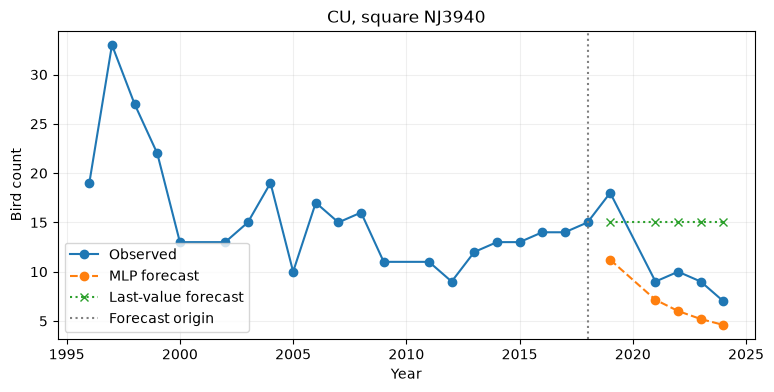

In [5]:
example_square = (
    mlp_report.predictions.groupby("OS_GRID_REF").size().sort_values(ascending=False).index[0]
)
obs = observations.loc[
    observations.OS_GRID_REF.eq(example_square)
    & observations.year.le(TEST_END_YEAR), ["year", task.target]
].sort_values("year")
mlp_pred = mlp_report.predictions.loc[
    mlp_report.predictions.OS_GRID_REF.eq(example_square)
].sort_values("year")
naive_pred = naive_report.predictions.loc[
    naive_report.predictions.OS_GRID_REF.eq(example_square)
].sort_values("year")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(obs.year, obs[task.target], "o-", label="Observed")
ax.plot(mlp_pred.year, mlp_pred.prediction, "o--", label="MLP forecast")
ax.plot(naive_pred.year, naive_pred.prediction, "x:", label="Last-value forecast")
ax.axvline(FORECAST_ORIGIN, color="grey", linestyle=":", label="Forecast origin")
ax.set(xlabel="Year", ylabel="Bird count", title=f"{SPECIES}, square {example_square}")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 6 · Save to existing prediction store (optional)

Results are saved in your model-hash folder with a per-species CSV and a manifest, so `03_plot_predictions.ipynb` can plot them. The `run_config` records the species, forecast origin, site selection, and test endpoint. Repeated runs with identical identities but different outputs are intentionally protected against accidental overwrite.

In [6]:
if SAVE_PREDICTIONS:
    run_config = {
        "species": SPECIES,
        "forecast_origin": FORECAST_ORIGIN,
        "test_end_year": TEST_END_YEAR,
        "max_sites": MAX_SITES,
        "dataset": data_path.name,
        "input_features": ["log1p(previous_year_count)", "previous_year_missing_flag"],
        "evaluation": "fixed_origin_recursive",
    }
    for name, params, report in [
        ("one_year_mlp", asdict(CONFIG), mlp_report),
        ("last_value_mlp_comparison", {}, naive_report),
    ]:
        folder = save_forecast_results(
            report,
            output_root=PROJECT_ROOT / "data" / "predictions",
            model_name=name,
            model_params=params,
            run_config=run_config,
            task=task,
        )
        print(f"Saved {name} -> {folder}")
else:
    print("Set SAVE_PREDICTIONS = True to save predictions.")

Set SAVE_PREDICTIONS = True to save predictions.


### Interpretation and limitations

- **Single-species global MLP:** shared weights across locations, but only the square's *own* previous count is input. It does not explicitly use spatial neighbours, site coordinates, climate, or other metadata yet.
- **Sparse surveys:** absent previous-year data are flagged rather than imputed as observed zero; true non-detections require explicit survey coverage to distinguish from sites not surveyed.
- **Recursive multi-year forecast:** the one-step model is trained on true historical inputs, then used on its own outputs at longer horizons. Errors may accumulate. Compare against the naive baseline on exactly the same evaluated rows.
- **No updating:** the network and observed inputs are frozen at `FORECAST_ORIGIN`. Actual test values never enter subsequent forecasts. Years with no bird observations are still simulated.
- **No hyperparameter tuning on the test period.** Choose layers/epochs using a separate validation period within the training years if you tune them.
- **Climate:** intentionally not part of this MLP; you can later extend the input features in another notebook without changing the shared evaluation or prediction-saving workflow.